### 🎓 Module 3: Multiple Linear Regression with Linear Algebra

In this Jupyter Notebook, we will see how to create our first simple **Multiple Linear Regression model using Linear Algebra (NumPy)** by implementing the famous **Normal Equation**, which solves the coefficients $b$ and $w_i$ all at once.

### AI and ML Concepts We Will Use:

* **Bias ($b$)**: The y-axis intercept term when $x$ = 0 (intercept, $\beta_0$)
* **Weights ($w_i$)**: Weights or coefficients associated with each feature (slopes of the hyperplane, $\beta_i$)
* **Features ($x_i$)**: Independent input variables used to describe the model (e.g., $x_1$ = study_hours)
* **N° Samples ($m$)**: Number of samples in the model (e.g., $m = 1000$ surveyed students)
* **N° Features ($n$)**: Number of features (e.g., $n = 4$ characteristics for each student: $x_1, x_2, x_3, x_4$)
* **Parameter Vector ($\beta$)**: Vector containing the bias and weights (e.g., $\beta = [b, w_i]$)
* **Design Matrix ($X$)**: Design matrix with dimensions $m \times (n+1)$. Its first column multiplies 1 by $b$, while the remaining columns contain the $x_i$ values multiplied by their corresponding $w_i$

### The Matrix Equation and the Normal Equation:

**1. The Matrix Equation**: This is the compact matrix formula for any number of $x_i$ features contained in the model:

$$\hat{y} = X\beta$$

**2. The Normal Equation**: Since $X$ is rectangular ($m \gg n$), it does not have an inverse. To find $\theta$, we orthogonally project the real vector $y$ onto the space spanned by $X$:

$$\theta = (X^T X)^{-1} X^T y$$

By multiplying the rectangular matrix by its own transpose ($X^T X$), linear algebra performs a double miracle:

* **Geometric:** It automatically minimizes the sum of squared errors, finding the optimal projection (the orthogonal projection).
* **Algebraic:** It transforms a rectangular and otherwise non-invertible structure into a perfectly square matrix of size $(n+1) \times (n+1)$.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Set plot styling for clean rendering (Matplotlib 3D Visualization)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. CREATE SYNTHETIC REAL-WORLD DATA ABOUT SOME STUDENTS

# y = Exam Score
# x1 = Study Hours
# x2 = Sleep Hours

# m = 10 number of samples (students)
# n = 2 number of features (x)

np.random.seed(42)

data = {
    'study_hours': [2.0, 3.5, 5.0, 7.0, 8.5, 4.0, 6.5, 9.0, 2.5, 6.0],
    'sleep_hours': [7.0, 6.5, 8.0, 6.0, 7.5, 5.5, 8.5, 6.0, 8.0, 7.0],
    'exam_score':  [55.0, 68.0, 78.0, 88.0, 95.0, 62.0, 85.0, 96.0, 58.0, 82.0]    
}

df = pd.DataFrame(data)
df.head(5)

,study_hours,sleep_hours,exam_score
0,2.0,7.0,55.0
1,3.5,6.5,68.0
2,5.0,8.0,78.0
3,7.0,6.0,88.0
4,8.5,7.5,95.0


In [2]:
# 2. BUILDING DISING MATRIX (X) AND VECTOR TARGET (y)

# Extract the real data y vector (shape: m x 1):
y = df['exam_score'].values.reshape(-1, 1)

# Extract feature values (shape: m x 2)
x_features = df[['study_hours', 'sleep_hours']].values

# Number of samples (m)
m = len(df)

# Create the Desing Matrix (X) by adding a bias column of ones (m x n+1 = 10 x 3)
bias_column = np.ones((m, 1))
X = np.hstack((bias_column, x_features))

print(f'Shape of Target Vector y: {y.shape}')
print(f'Shape of Design Matrix X: {X.shape}')
print('\nFirst 5 rows of Design Matrix X:')
print(X[:5])

Shape of Target Vector y: (10, 1)
Shape of Design Matrix X: (10, 3)

First 5 rows of Design Matrix X:
[[1.  2.  7. ]
 [1.  3.5 6.5]
 [1.  5.  8. ]
 [1.  7.  6. ]
 [1.  8.5 7.5]]


In [3]:
# 3. FIND THE OPTIMAL PARAMETERS (BETA VECTOR) BY SOLVING THE NORMAL EQUATION
# BETA = (X^T * X)^-1 * X^T*y

# Step 1: Calculate X^T * X (shape: 3x3)
XtX = X.T @ X

# Step 2: Inverse of the step 1 expresion (shape: 3x3)
XtX_inv = np.linalg.inv(XtX)

# Step 3: Calculate X^T*y (shape: 3x1)
Xty = X.T @ y

# Step 4: Calculate the final expression and solve Parameter Beta Vector:
beta = XtX_inv @ Xty

# Extract individual parameters b, w1, w2:
b = beta[0, 0]      # Bias
w1 = beta[1, 0]     # Weight for study_hours
w2 = beta[2, 0]     # Weight for sleep_hours

print('--- Normal Equation Results ---')
print(f'Bias (b): {b:.4f}')
print(f'Weight 1 (w1 - Study Hours): {w1:.4f}')
print(f'Weight 2 (w2 - Sleep Hours): {w2:.4f}')
print(f'\nMathematical Model Equation:')
print(f'y_hat = {b:.2f} + {w1:.2f}*x1 + {w2:.2f}*x2')

--- Normal Equation Results ---
Bias (b): 32.3966
Weight 1 (w1 - Study Hours): 6.1963
Weight 2 (w2 - Sleep Hours): 1.5491

Mathematical Model Equation:
y_hat = 32.40 + 6.20*x1 + 1.55*x2


In [4]:
# 4. PREDICTIONS, RESIDUALS AND MEAN SQUEARED ERROR

# Compute the prediction model (y_hat = X*B)
y_hat = X @ beta

# Compute vector of residual errors between y and y_hat (e = y-y_hat)
e = y - y_hat

# Compute Mean Squared Errors (MSE)
MSE = np.mean(e**2)

# Store results in the DataFrame and show it
df['predicted_score'] = y_hat.flatten()
df['residual_error'] = e.flatten()

print('Mean Squared Error (MSE): {mse:.4f} \n')
print('--- Predictions vs Actual Values ---')
print(df.round(2))


Mean Squared Error (MSE): {mse:.4f} 

--- Predictions vs Actual Values ---
   study_hours  sleep_hours  exam_score  predicted_score  residual_error
0          2.0          7.0        55.0            55.63           -0.63
1          3.5          6.5        68.0            64.15            3.85
2          5.0          8.0        78.0            75.77            2.23
3          7.0          6.0        88.0            85.06            2.94
4          8.5          7.5        95.0            96.68           -1.68
5          4.0          5.5        62.0            65.70           -3.70
6          6.5          8.5        85.0            85.84           -0.84
7          9.0          6.0        96.0            97.46           -1.46
8          2.5          8.0        58.0            60.28           -2.28
9          6.0          7.0        82.0            80.42            1.58


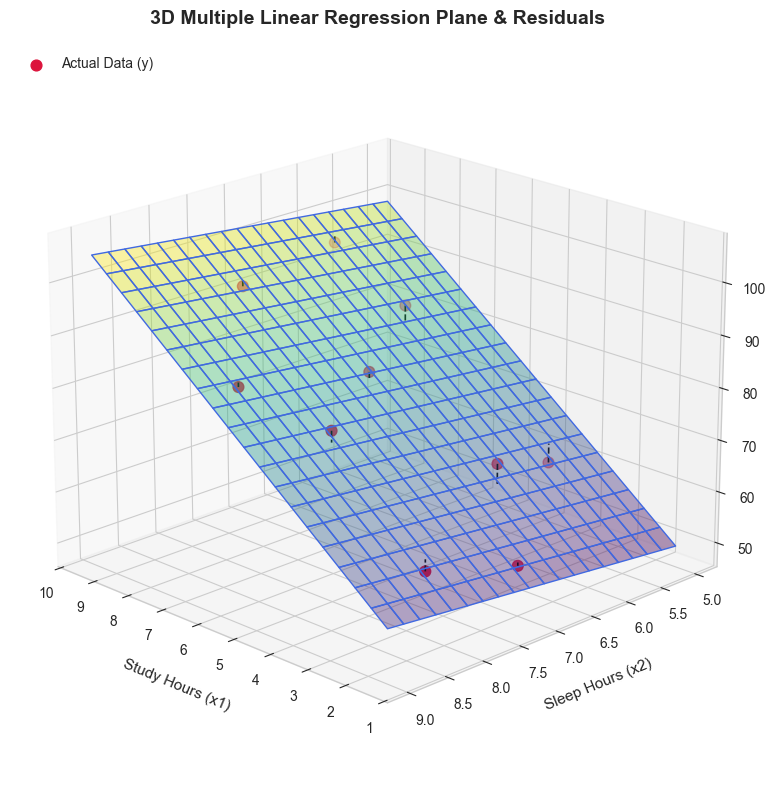

In [5]:
# 5. MATPLOTLIB VISUALIZATION 3D OF EACH FEATURE

# Create 3D figure and axis
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# 1. Plot actual data points
x1_data = df['study_hours']
x2_data = df['sleep_hours']
y_data = df['exam_score']

ax.scatter(x1_data, x2_data, y_data, color='crimson', s=60, label='Actual Data (y)', zorder=5)

# 2. Generate a 2D grid of points to render the regression hyperplane
x1_surf = np.linspace(x1_data.min() - 0.5, x1_data.max() + 0.5, 20)
x2_surf = np.linspace(x2_data.min() - 0.5, x2_data.max() + 0.5, 20)
X1_mesh, X2_mesh = np.meshgrid(x1_surf, x2_surf)

# Calculate predicted height (y_hat) for every coordinate pair in the grid
Y_mesh = b + w1 * X1_mesh + w2 * X2_mesh

# Render the fitted 3D plane
surf = ax.plot_surface(X1_mesh, X2_mesh, Y_mesh, color='royalblue', alpha=0.4, cmap='viridis', antialiased=True)

# 3. Draw vertical residual line segments (e = y - y_hat)
for i in range(len(df)):
    x1_i = x1_data[i]
    x2_i = x2_data[i]
    y_act = y_data[i]
    y_fit = df['predicted_score'][i]
    ax.plot([x1_i, x1_i], [x2_i, x2_i], [y_act, y_fit], color='black', linestyle='--', linewidth=1.2)

# Set axis labels and plot title
ax.set_xlabel('Study Hours (x1)', fontsize=11, labelpad=10)
ax.set_ylabel('Sleep Hours (x2)', fontsize=11, labelpad=10)
ax.set_zlabel('Exam Score (y)', fontsize=11, labelpad=10)
ax.set_title('3D Multiple Linear Regression Plane & Residuals', fontsize=14, fontweight='bold', pad=15)

# Orient camera angle for optimal 3D perspective
ax.view_init(elev=20, azim=135)

plt.legend(loc='upper left')
plt.tight_layout()
plt.show()